# Charm Production Cross-Section Ratio: $\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$ vs $E_\nu$

This notebook loads and visualizes the inclusive charm production rate $\sigma_{\mathrm{charm}} / \sigma_{\mathrm{CC}}$ as a function of neutrino energy $E_\nu$, reproducing the comparison between:
- **SND@LHC MC Inclusive** ($\nu_\mu + \bar{\nu}_\mu$)
- **Historical Emulsion Measurements**: **CHORUS** (2011, $\nu_\mu$) and **E531** (1988, $\nu_\mu$)
- **LHAPDF nCTEQ15 Theoretical Predictions**: Evaluated for a nuclear emulsion target ($\langle Z/A \rangle \approx 0.467$)
- **Cumulative $1\sigma$ Uncertainty Belts**:
  - **Base Kinematics $1\sigma$**: Charm pole mass $m_c = 1.43 \pm 0.10\ \mathrm{GeV}$ & CKM $|V_{cd}| = 0.221 \pm 0.004$
  - **LHAPDF nCTEQ15 $1\sigma$**: Nuclear PDF eigenvector variations & QCD evolution

Inputs can be loaded either directly from the ROOT results file (`/eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root`) via `ddfUtils.root.converters.to_numpy` or from the standalone precalculated LHAPDF prediction CSV files (`/eos/user/i/idioniso/snd-numu-charm/data/predictions/`).

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplhep as hep
import ROOT

ROOT.gROOT.SetBatch(True)
ROOT.gStyle.SetOptStat(0)
ROOT.gStyle.SetOptTitle(0)

import ddfUtils.root as dur
import ddfUtils.mpl_styling as dms
import ddfUtils.stats as dstats

print("Environment initialized: ROOT, mplhep, and ddfUtils ready.")

Environment initialized: ROOT, mplhep, and ddfUtils ready.


In [2]:
# -------------------------------------------------------------------------
# File Paths Configuration
# -------------------------------------------------------------------------
ROOT_CANDIDATES = [
    "/eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root",
    "../plots/charm_diagnostic_results.root",
    "plots/charm_diagnostic_results.root",
    "charm_diagnostic_results.root",
]

PRED_DIR_CANDIDATES = [
    "/eos/user/i/idioniso/snd-numu-charm/data/predictions",
    "../scripts/diagnostics/predictions",
    "scripts/diagnostics/predictions",
    "/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions",
]

MEAS_DIR_CANDIDATES = [
    "/eos/user/i/idioniso/snd-numu-charm/data/measurements",
    "../scripts/diagnostics/measurements",
    "scripts/diagnostics/measurements",
    "/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/measurements",
]

root_path = next((p for p in ROOT_CANDIDATES if os.path.exists(p)), None)
pred_dir = next((p for p in PRED_DIR_CANDIDATES if os.path.exists(p)), None)
meas_dir = next((p for p in MEAS_DIR_CANDIDATES if os.path.exists(p)), None)

print(f"ROOT file path:        {root_path}")
print(f"Predictions directory: {pred_dir}")
print(f"Measurements directory: {meas_dir}")


ROOT file path:        /eos/user/i/idioniso/snd-numu-charm/plots/charm_diagnostic_results.root
Predictions directory: /eos/user/i/idioniso/snd-numu-charm/data/predictions
Measurements directory: /eos/user/i/idioniso/snd-numu-charm/data/measurements


In [3]:
# -------------------------------------------------------------------------
# Method 1: Load Data from ROOT via ddfUtils (dur.converters.to_numpy)
# -------------------------------------------------------------------------
def load_charm_rate_from_root(filepath: str, option: str = "inclusive"):
    f = ROOT.TFile.Open(filepath)
    if not f or f.IsZombie():
        raise FileNotFoundError(f"Could not open ROOT file at {filepath}")
    
    summary = f.Get("Summary")
    if not summary:
        raise KeyError("Directory 'Summary' not found in ROOT file.")
    
    # 1. MC Inclusive data points (TGraphAsymmErrors)
    if option.lower() in ["nu", "neutrino"]:
        g_mc = summary.Get("g_charm_rate_mc_nu")
    elif option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"]:
        g_mc = summary.Get("g_charm_rate_mc_antinu")
    else:
        g_mc = summary.Get("g_charm_rate_mc")
    mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh = dur.converters.to_numpy(g_mc)
    
    # 2. CHORUS measurement (TGraphErrors)
    g_chorus = summary.Get("g_chorus_measurement")
    ch_res = dur.converters.to_numpy(g_chorus)
    if len(ch_res) == 4:
        ch_x, ch_y, ch_ex, ch_ey = ch_res
        ch_exl, ch_exh, ch_eyl, ch_eyh = ch_ex, ch_ex, ch_ey, ch_ey
    else:
        ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh = ch_res
        
    # 3. E531 measurement (TGraphAsymmErrors)
    g_e531 = summary.Get("g_e531_measurement")
    e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh = dur.converters.to_numpy(g_e531)
    
    # 4. LHAPDF Central Prediction (TGraph)
    if option.lower() in ["nu", "neutrino"]:
        g_qcd = summary.Get("g_lhapdf_prediction_nu")
        g_inner = summary.Get("g_lhapdf_nu_1sigma_inner_band")
        g_outer = summary.Get("g_lhapdf_nu_1sigma_outer_band")
    elif option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"]:
        g_inner = summary.Get("g_lhapdf_antinu_1sigma_inner_band")
        g_outer = summary.Get("g_lhapdf_antinu_1sigma_outer_band")
        g_qcd = summary.Get("g_lhapdf_prediction_antinu")
    else:
        g_qcd = summary.Get("g_lhapdf_prediction_inclusive")
        g_inner = summary.Get("g_lhapdf_inclusive_1sigma_inner_band")
        g_outer = summary.Get("g_lhapdf_inclusive_1sigma_outer_band")
    
    qcd_x, qcd_y = dur.converters.to_numpy(g_qcd)
    in_x, in_y, in_exl, in_exh, in_eyl, in_eyh = dur.converters.to_numpy(g_inner)
    out_x, out_y, out_exl, out_exh, out_eyl, out_eyh = dur.converters.to_numpy(g_outer)
    
    return {
        "mc": (mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh),
        "chorus": (ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh),
        "e531": (e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh),
        "qcd": (qcd_x, qcd_y),
        "inner_band": (in_x, in_y, in_eyl, in_eyh),
        "outer_band": (out_x, out_y, out_eyl, out_eyh),
    }

In [4]:
def load_charm_rate_from_csv(pred_directory: str, meas_directory: str, option: str = "inclusive", target: str = "emulsion"):
    option_map = {
        "inclusive": {
            "pred_file": "inclusive_numu_antinumu_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "inclusive"
        },
        "nu": {
            "pred_file": "numuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "inclusive"
        },
        "anti-nu": {
            "pred_file": "antinumuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
            "meas_channel": "anti_nu"
        }
    }
    
    cfg = option_map.get(option)
    if not cfg:
        raise ValueError(f"Unknown option '{option}'. Choose from: {list(option_map.keys())}")
    
    # 1. Load LHAPDF theory prediction
    pred_csv = os.path.join(pred_directory, cfg["pred_file"])
    if not os.path.exists(pred_csv):
        raise FileNotFoundError(f"Prediction file not found: {pred_csv}")
        
    df_pred = pd.read_csv(pred_csv)
    
    # Determine column naming scheme (supports target-prefixed or legacy columns)
    pfx = f"{target}_" if f"{target}_ratio_central" in df_pred.columns else ""
    
    qcd_x = df_pred["E_nu_GeV"].to_numpy()
    qcd_y = df_pred[f"{pfx}ratio_central"].to_numpy()
    in_eyl = df_pred[f"{pfx}base_unc_low"].to_numpy()
    in_eyh = df_pred[f"{pfx}base_unc_high"].to_numpy()
    out_eyl = df_pred[f"{pfx}total_unc_low"].to_numpy()
    out_eyh = df_pred[f"{pfx}total_unc_high"].to_numpy()
    
    # 2. Load historical benchmark measurements
    meas_csv = os.path.join(meas_directory, "neutrino_charm_cross_section_ratio_vs_enu.csv")
    df_meas = pd.read_csv(meas_csv, comment="#")
    
    target_channel = cfg["meas_channel"]
    ch_mask = (df_meas["experiment"].str.strip() == "CHORUS")
    e5_mask = (df_meas["experiment"].str.strip() == "E531")
    
    if "channel" in df_meas.columns:
        channel_col = df_meas["channel"].str.strip()
        ch_sub = df_meas[ch_mask & (channel_col == target_channel)]
        e5_sub = df_meas[e5_mask & (channel_col == target_channel)]
        if ch_sub.empty:
            ch_sub = df_meas[ch_mask & (channel_col == "inclusive")]
        if e5_sub.empty:
            e5_sub = df_meas[e5_mask & (channel_col == "inclusive")]
    else:
        ch_sub = df_meas[ch_mask]
        e5_sub = df_meas[e5_mask]
    
    return {
        "qcd": (qcd_x, qcd_y),
        "inner_band": (qcd_x, qcd_y, in_eyl, in_eyh),
        "outer_band": (qcd_x, qcd_y, out_eyl, out_eyh),
        "chorus": (
            ch_sub["E_nu_GeV"].to_numpy(), ch_sub["ratio"].to_numpy(),
            ch_sub["dx_low"].to_numpy(), ch_sub["dx_high"].to_numpy(),
            ch_sub["dy_low"].to_numpy(), ch_sub["dy_high"].to_numpy()
        ),
        "e531": (
            e5_sub["E_nu_GeV"].to_numpy(), e5_sub["ratio"].to_numpy(),
            e5_sub["dx_low"].to_numpy(), e5_sub["dx_high"].to_numpy(),
            e5_sub["dy_low"].to_numpy(), e5_sub["dy_high"].to_numpy()
        ),
    }

In [12]:
data_root = load_charm_rate_from_root(root_path, option="inclusive")
mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh = data_root["mc"]

# Emulsion prediction (nu-only, matching E531 & CHORUS beams)
data_emulsion = load_charm_rate_from_csv(pred_dir, meas_dir, option="nu", target="emulsion")
em_qcd_x, em_qcd_y = data_emulsion["qcd"]
em_in_x, em_in_y, em_in_eyl, em_in_eyh = data_emulsion["inner_band"]
em_out_x, em_out_y, em_out_eyl, em_out_eyh = data_emulsion["outer_band"]

# Historical data points (from emulsion nu-mode)
ch_x, ch_y, ch_exl, ch_exh, ch_eyl, ch_eyh = data_emulsion["chorus"]
e5_x, e5_y, e5_exl, e5_exh, e5_eyl, e5_eyh = data_emulsion["e531"]

# Tungsten prediction (nu + anti-nu inclusive, matching SND@LHC target)
data_tungsten = load_charm_rate_from_csv(pred_dir, meas_dir, option="inclusive", target="tungsten")
w_qcd_x, w_qcd_y = data_tungsten["qcd"]
w_in_x, w_in_y, w_in_eyl, w_in_eyh = data_tungsten["inner_band"]
w_out_x, w_out_y, w_out_eyl, w_out_eyh = data_tungsten["outer_band"]

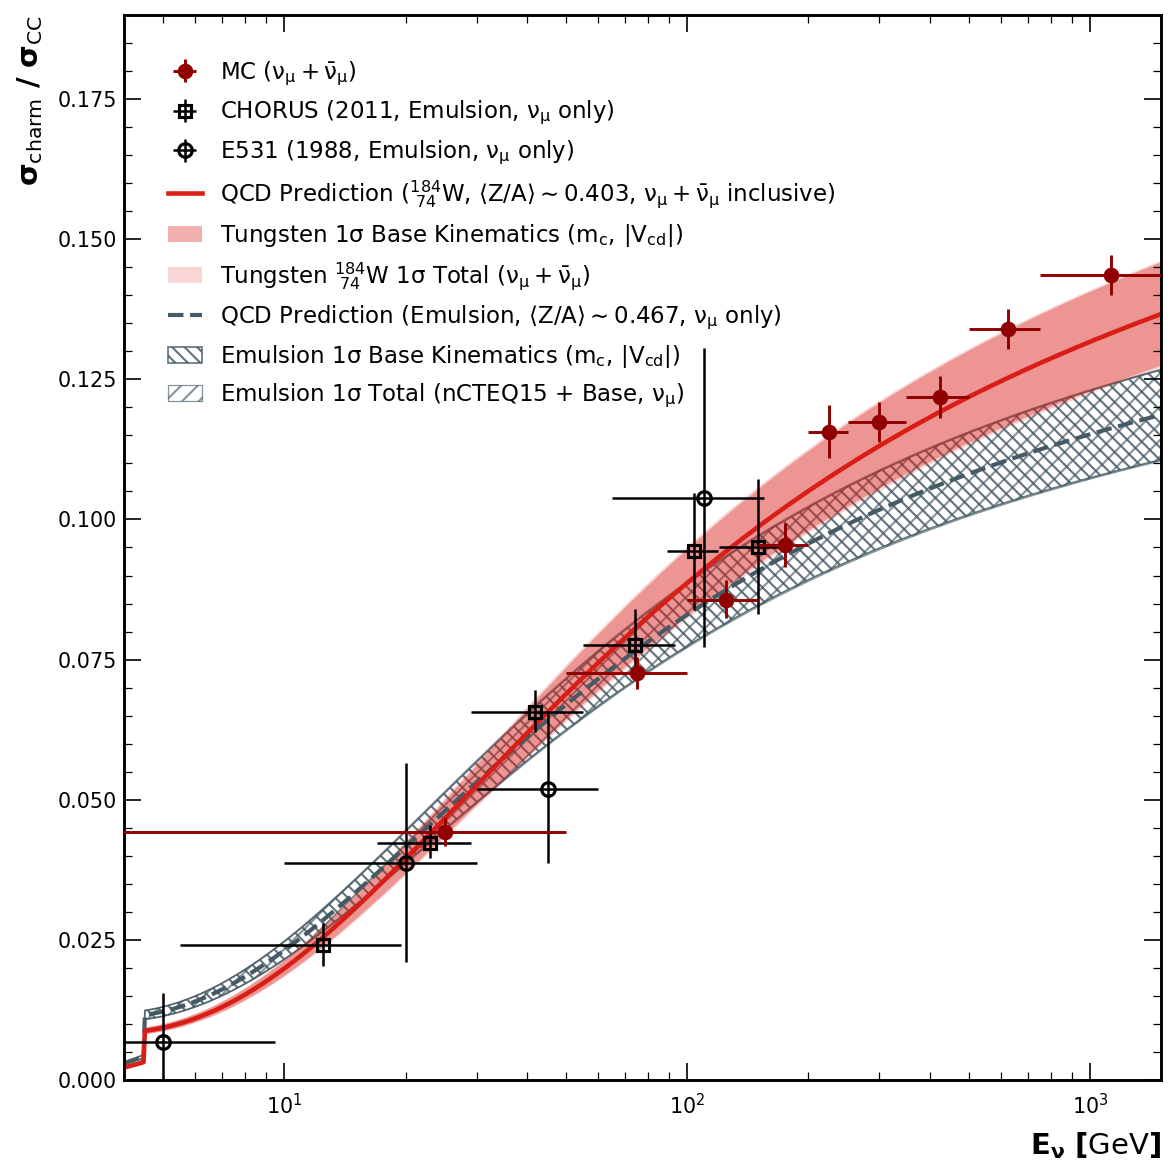

In [13]:
# -------------------------------------------------------------------------
# Publication-Quality Reproduction Plot (Matplotlib + HEP Styling)
# -------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

c_w = "#d91e18"       # Crimson red for Tungsten
c_em = "#455a64"      # Slate blue-gray for Emulsion

# A. Emulsion Prediction (Dashed line + Hatched bands)
h_em_out = ax.fill_between(
    em_out_x, em_out_y - em_out_eyl, em_out_y + em_out_eyh,
    facecolor="none", edgecolor=c_em, hatch="///", linewidth=0.6, alpha=0.65,
    label=r"Emulsion $1\sigma$ Total (nCTEQ15 + Base, $\nu_\mu$)"
)
h_em_in = ax.fill_between(
    em_in_x, em_in_y - em_in_eyl, em_in_y + em_in_eyh,
    facecolor="none", edgecolor=c_em, hatch=r"\\\\", linewidth=0.8, alpha=0.85,
    label=r"Emulsion $1\sigma$ Base Kinematics ($m_c,\, |V_{cd}|$)"
)
(h_em_qcd,) = ax.plot(
    em_qcd_x, em_qcd_y,
    color=c_em, lw=2.0, linestyle="--",
    label=r"QCD Prediction (Emulsion, $\langle Z/A\rangle \sim 0.467$, $\nu_\mu$ only)"
)

# B. Tungsten Prediction (Solid line + Solid transparent fills)
h_w_out = ax.fill_between(
    w_out_x, w_out_y - w_out_eyl, w_out_y + w_out_eyh,
    color=c_w, alpha=0.18, edgecolor="none",
    label=r"Tungsten $^{184}_{\ 74}\mathrm{W}\ 1\sigma$ Total ($\nu_\mu + \bar{\nu}_\mu$)"
)
h_w_in = ax.fill_between(
    w_in_x, w_in_y - w_in_eyl, w_in_y + w_in_eyh,
    color=c_w, alpha=0.35, edgecolor="none",
    label=r"Tungsten $1\sigma$ Base Kinematics ($m_c,\, |V_{cd}|$)"
)
(h_w_qcd,) = ax.plot(
    w_qcd_x, w_qcd_y,
    color=c_w, lw=2.2, linestyle="-",
    label=r"QCD Prediction ($^{184}_{\ 74}\mathrm{W}$, $\langle Z/A\rangle \sim 0.403$, $\nu_\mu + \bar{\nu}_\mu$ inclusive)"
)

# C. Historical Measurements (Emulsion, nu-only)
h_e531 = ax.errorbar(
    e5_x, e5_y, xerr=[e5_exl, e5_exh], yerr=[e5_eyl, e5_eyh],
    fmt="o", color="black", mfc="none", mec="black", mew=1.5,
    markersize=6.5, elinewidth=1.2, capsize=0, zorder=5,
    label=r"E531 (1988, Emulsion, $\nu_\mu$ only)"
)
h_chorus = ax.errorbar(
    ch_x, ch_y, xerr=[ch_exl, ch_exh], yerr=[ch_eyl, ch_eyh],
    fmt="s", color="black", mfc="none", mec="black", mew=1.5,
    markersize=6.0, elinewidth=1.2, capsize=0, zorder=5,
    label=r"CHORUS (2011, Emulsion, $\nu_\mu$ only)"
)

# D. Monte Carlo Data Points (nu-only)
h_mc = ax.errorbar(
    mc_x, mc_y, xerr=[mc_exl, mc_exh], yerr=[mc_eyl, mc_eyh],
    fmt="o", color="#910000", mfc="#910000", mec="#910000", mew=1.5,
    markersize=6.0, elinewidth=1.4, capsize=0, zorder=6,
    label=r"MC ($\nu_\mu + \bar \nu_\mu$)"
)

# Layout, Labels, and Legend Positioning
ax.set_xscale("log")
ax.set_xlim(4.0, 1500.0)
ax.set_ylim(0.0, 0.19)

ax.set_xlabel(r"$E_\nu\ [\mathrm{GeV}]$", fontsize=14, loc="right", labelpad=6)
ax.set_ylabel(r"$\sigma_{\mathrm{charm}}\ /\ \sigma_{\mathrm{CC}}$", fontsize=14, loc="top", labelpad=6)

legend_handles = [
    h_mc, h_chorus, h_e531,
    h_w_qcd, h_w_in, h_w_out,
    h_em_qcd, h_em_in, h_em_out
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    frameon=False,
    facecolor="white",
    framealpha=0.92,
    fontsize=11,
)

plt.tight_layout()
plt.show()

# Charm Dimuon Cross-Section Ratio: $\sigma_{\mathrm{charm}, 2\mu} / \sigma_{\mathrm{CC}}$ vs $E_\nu$

This section visualizes the semi-muonic charm decay (dimuon) production rate $\sigma_{\mathrm{charm}, 2\mu} / \sigma_{\mathrm{CC}}$ as a function of neutrino energy $E_\nu$, comparing:
- **SND@LHC MC Dimuon CC** ($\nu_\mu$ and inclusive)
- **Historical Benchmark Measurements**:
  - **NOMAD** (2013, $\nu_\mu$ CC, open diamond)
  - **CHORUS** (2011, $\nu_\mu$ CC, open square)
  - **CCFR** (1995, $\nu_\mu$ CC, open circle)
  - **E53A+E53B** (1983, $\nu_\mu$ CC, open triangle)
- **Theoretical LHAPDF Predictions**:
  - $^{184}\mathrm{W}$ Target (solid curve, transparent $1\sigma$ base and total bands)
  - Emulsion Target (dashed curve, hatched $1\sigma$ base and total bands)


In [7]:
# -------------------------------------------------------------------------
# Method 1 for Dimuon: Load Data from ROOT via ddfUtils (dur.converters.to_numpy)
# -------------------------------------------------------------------------
def load_dimuon_rate_from_root(filepath: str, option: str = "nu", target: str = "tungsten"):
    f = ROOT.TFile.Open(filepath)
    if not f or f.IsZombie():
        raise FileNotFoundError(f"Could not open ROOT file at {filepath}")
    
    summary = f.Get("Summary")
    if not summary:
        raise KeyError("Directory Summary not found in ROOT file.")
    
    # 1. MC Dimuon points (TGraphAsymmErrors)
    if option.lower() in ["nu", "neutrino"]:
        g_mc = summary.Get("g_dimuon_rate_mc_nu")
    elif option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"]:
        g_mc = summary.Get("g_dimuon_rate_mc_antinu")
    else:
        g_mc = summary.Get("g_dimuon_rate_mc")
        
    mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh = dur.converters.to_numpy(g_mc)
    
    # 2. Historical Dimuon Measurements
    exp_graphs = {
        "NOMAD": summary.Get("g_dimuon_nomad"),
        "CHORUS": summary.Get("g_dimuon_chorus"),
        "CCFR": summary.Get("g_dimuon_ccfr"),
        "E53A+E53B": summary.Get("g_dimuon_e53a_e53b"),
    }
    measurements = {}
    for exp_name, g_exp in exp_graphs.items():
        if g_exp:
            measurements[exp_name] = dur.converters.to_numpy(g_exp)
            
    # 3. LHAPDF Dimuon Prediction
    opt_key = "nu" if option.lower() in ["nu", "neutrino"] else ("antinu" if option.lower() in ["antinu", "anti-nu", "antineutrino", "anti-neutrino"] else "inclusive")
    
    tgt_suffix = f"_{target.lower()}"
    g_qcd = summary.Get(f"g_lhapdf_dimuon_prediction_{opt_key}{tgt_suffix}") or summary.Get(f"g_lhapdf_dimuon_prediction_{opt_key}")
    g_base = summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_base_band{tgt_suffix}") or summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_base_band")
    g_total = summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_total_band{tgt_suffix}") or summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_total_band")
    
    qcd_x, qcd_y = dur.converters.to_numpy(g_qcd)
    _, _, _, _, in_eyl, in_eyh = dur.converters.to_numpy(g_base)
    _, _, _, _, out_eyl, out_eyh = dur.converters.to_numpy(g_total)
    
    # Emulsion predictions if present
    em_data = None
    g_qcd_em = summary.Get(f"g_lhapdf_dimuon_prediction_{opt_key}_emulsion")
    if g_qcd_em:
        g_base_em = summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_base_band_emulsion")
        g_total_em = summary.Get(f"g_lhapdf_dimuon_{opt_key}_1sigma_total_band_emulsion")
        em_x, em_y = dur.converters.to_numpy(g_qcd_em)
        _, _, _, _, em_in_eyl, em_in_eyh = dur.converters.to_numpy(g_base_em)
        _, _, _, _, em_out_eyl, em_out_eyh = dur.converters.to_numpy(g_total_em)
        em_data = {
            "qcd": (em_x, em_y),
            "base_band": (em_x, em_y, em_in_eyl, em_in_eyh),
            "total_band": (em_x, em_y, em_out_eyl, em_out_eyh),
        }
        
    res = {
        "mc": (mc_x, mc_y, mc_exl, mc_exh, mc_eyl, mc_eyh),
        "measurements": measurements,
        "qcd": (qcd_x, qcd_y),
        "base_band": (qcd_x, qcd_y, in_eyl, in_eyh),
        "total_band": (qcd_x, qcd_y, out_eyl, out_eyh),
    }
    if em_data:
        res["emulsion"] = em_data
    return res


In [8]:
# -------------------------------------------------------------------------
# Method 2 for Dimuon: Load Data from CSV Predictions and Measurements
# -------------------------------------------------------------------------
def load_dimuon_rate_from_csv(pred_directory: str, meas_directory: str, option: str = "nu", target: str = "tungsten"):
    option_map = {
        "inclusive": "neutrino_charm_dimuon_ratio_inclusive_prediction_lhapdf.csv",
        "nu": "neutrino_charm_dimuon_ratio_nu_prediction_lhapdf.csv",
        "anti-nu": "neutrino_charm_dimuon_ratio_antinu_prediction_lhapdf.csv",
    }
    pred_file = option_map.get(option.lower())
    if not pred_file:
        raise ValueError(f"Unknown option {option}. Choose from: {list(option_map.keys())}")
        
    # 1. Load LHAPDF dimuon theory prediction
    pred_csv = os.path.join(pred_directory, pred_file)
    if not os.path.exists(pred_csv):
        raise FileNotFoundError(f"Prediction file not found: {pred_csv}")
        
    df_pred = pd.read_csv(pred_csv)
    qcd_x = df_pred["E_nu_GeV"].to_numpy()
    
    # Target prefix resolution (values in predictions are in units of 10^-3)
    pref = f"{target.lower()}_" if f"{target.lower()}_ratio_nominal_10m3" in df_pred.columns else ""
    cen_col = f"{pref}ratio_nominal_10m3" if f"{pref}ratio_nominal_10m3" in df_pred.columns else "ratio_nominal_10m3"
    b_lo_col = f"{pref}sigma_1_lo" if f"{pref}sigma_1_lo" in df_pred.columns else "sigma_1_lo"
    b_hi_col = f"{pref}sigma_1_hi" if f"{pref}sigma_1_hi" in df_pred.columns else "sigma_1_hi"
    t_lo_col = f"{pref}sigma_4_lo" if f"{pref}sigma_4_lo" in df_pred.columns else "sigma_4_lo"
    t_hi_col = f"{pref}sigma_4_hi" if f"{pref}sigma_4_hi" in df_pred.columns else "sigma_4_hi"
    
    scale = 1e-3
    qcd_y = df_pred[cen_col].to_numpy() * scale
    in_eyl = df_pred[b_lo_col].to_numpy() * scale
    in_eyh = df_pred[b_hi_col].to_numpy() * scale
    out_eyl = df_pred[t_lo_col].to_numpy() * scale
    out_eyh = df_pred[t_hi_col].to_numpy() * scale
    
    # Check if emulsion columns also exist
    em_data = None
    if "emulsion_ratio_nominal_10m3" in df_pred.columns:
        em_y = df_pred["emulsion_ratio_nominal_10m3"].to_numpy() * scale
        em_in_eyl = df_pred["emulsion_sigma_1_lo"].to_numpy() * scale
        em_in_eyh = df_pred["emulsion_sigma_1_hi"].to_numpy() * scale
        em_out_eyl = df_pred["emulsion_sigma_4_lo"].to_numpy() * scale
        em_out_eyh = df_pred["emulsion_sigma_4_hi"].to_numpy() * scale
        em_data = {
            "qcd": (qcd_x, em_y),
            "base_band": (qcd_x, em_y, em_in_eyl, em_in_eyh),
            "total_band": (qcd_x, em_y, em_out_eyl, em_out_eyh),
        }
        
    # 2. Load historical benchmark measurements (NOMAD, CHORUS, CCFR, E53A+E53B)
    meas_csv = os.path.join(meas_directory, "neutrino_charm_dimuon_ratio_vs_enu.csv")
    df_meas = pd.read_csv(meas_csv, comment="#")
    
    measurements = {}
    for exp_name in ["NOMAD", "CHORUS", "CCFR", "E53A+E53B"]:
        sub = df_meas[df_meas["experiment"].str.strip() == exp_name]
        if not sub.empty:
            x_val = sub["E_nu_GeV"].to_numpy()
            dx_lo = sub["dx_low"].to_numpy()
            dx_hi = sub["dx_high"].to_numpy()
            y_val = sub["ratio_times_10^-3"].to_numpy() * scale
            dy_lo = sub["dy_low"].to_numpy() * scale
            dy_hi = sub["dy_high"].to_numpy() * scale
            measurements[exp_name] = (x_val, y_val, dx_lo, dx_hi, dy_lo, dy_hi)
            
    res = {
        "measurements": measurements,
        "qcd": (qcd_x, qcd_y),
        "base_band": (qcd_x, qcd_y, in_eyl, in_eyh),
        "total_band": (qcd_x, qcd_y, out_eyl, out_eyh),
    }
    if em_data:
        res["emulsion"] = em_data
    return res


In [ ]:
data_dimuon_root = {
    o: load_dimuon_rate_from_root(root_path, option=o) for o in ("inclusive", "nu", "anti-nu")
}

# 1. Unpack MC coordinates into dictionaries keyed by channel option:
dim_mc = {o: data_dimuon_root[o]["mc"] for o in ("inclusive", "nu", "anti-nu")}

dim_mc_x   = {o: dim_mc[o][0] for o in dim_mc}
dim_mc_y   = {o: dim_mc[o][1] for o in dim_mc}
dim_mc_exl = {o: dim_mc[o][2] for o in dim_mc}
dim_mc_exh = {o: dim_mc[o][3] for o in dim_mc}
dim_mc_eyl = {o: dim_mc[o][4] for o in dim_mc}
dim_mc_eyh = {o: dim_mc[o][5] for o in dim_mc}

# 2. Historical measurements & Tungsten predictions from CSV
data_dimuon_w = {
    o: load_dimuon_rate_from_csv(pred_dir, meas_dir, option=o, target="tungsten") for o in ("inclusive", "nu", "anti-nu")
}
dim_measurements = {o: data_dimuon_w[o]["measurements"] for o in ("inclusive", "nu", "anti-nu")}

dim_w_qcd_x = {o: data_dimuon_w[o]["qcd"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_w_qcd_y = {o: data_dimuon_w[o]["qcd"][1] for o in ("inclusive", "nu", "anti-nu")}

dim_w_in_x   = {o: data_dimuon_w[o]["base_band"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_w_in_y   = {o: data_dimuon_w[o]["base_band"][1] for o in ("inclusive", "nu", "anti-nu")}
dim_w_in_eyl = {o: data_dimuon_w[o]["base_band"][2] for o in ("inclusive", "nu", "anti-nu")}
dim_w_in_eyh = {o: data_dimuon_w[o]["base_band"][3] for o in ("inclusive", "nu", "anti-nu")}

dim_w_out_x   = {o: data_dimuon_w[o]["total_band"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_w_out_y   = {o: data_dimuon_w[o]["total_band"][1] for o in ("inclusive", "nu", "anti-nu")}
dim_w_out_eyl = {o: data_dimuon_w[o]["total_band"][2] for o in ("inclusive", "nu", "anti-nu")}
dim_w_out_eyh = {o: data_dimuon_w[o]["total_band"][3] for o in ("inclusive", "nu", "anti-nu")}

# 3. Emulsion predictions from CSV
data_dimuon_em = {
    o: load_dimuon_rate_from_csv(pred_dir, meas_dir, option=o, target="emulsion") for o in ("inclusive", "nu", "anti-nu")
}
dim_em_qcd_x = {o: data_dimuon_em[o]["qcd"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_em_qcd_y = {o: data_dimuon_em[o]["qcd"][1] for o in ("inclusive", "nu", "anti-nu")}

dim_em_in_x   = {o: data_dimuon_em[o]["base_band"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_em_in_y   = {o: data_dimuon_em[o]["base_band"][1] for o in ("inclusive", "nu", "anti-nu")}
dim_em_in_eyl = {o: data_dimuon_em[o]["base_band"][2] for o in ("inclusive", "nu", "anti-nu")}
dim_em_in_eyh = {o: data_dimuon_em[o]["base_band"][3] for o in ("inclusive", "nu", "anti-nu")}

dim_em_out_x   = {o: data_dimuon_em[o]["total_band"][0] for o in ("inclusive", "nu", "anti-nu")}
dim_em_out_y   = {o: data_dimuon_em[o]["total_band"][1] for o in ("inclusive", "nu", "anti-nu")}
dim_em_out_eyl = {o: data_dimuon_em[o]["total_band"][2] for o in ("inclusive", "nu", "anti-nu")}
dim_em_out_eyh = {o: data_dimuon_em[o]["total_band"][3] for o in ("inclusive", "nu", "anti-nu")}

print(f"Extracted MC dimuon points across channels: {[len(dim_mc_x[o]) for o in dim_mc_x]}")
print(f"Loaded Tungsten prediction grid points: {[len(dim_w_qcd_x[o]) for o in dim_w_qcd_x]}")
print(f"Loaded Emulsion prediction grid points: {[len(dim_em_qcd_x[o]) for o in dim_em_qcd_x]}")


ValueError: Unknown option antinu. Choose from: ['inclusive', 'nu', 'anti-nu']

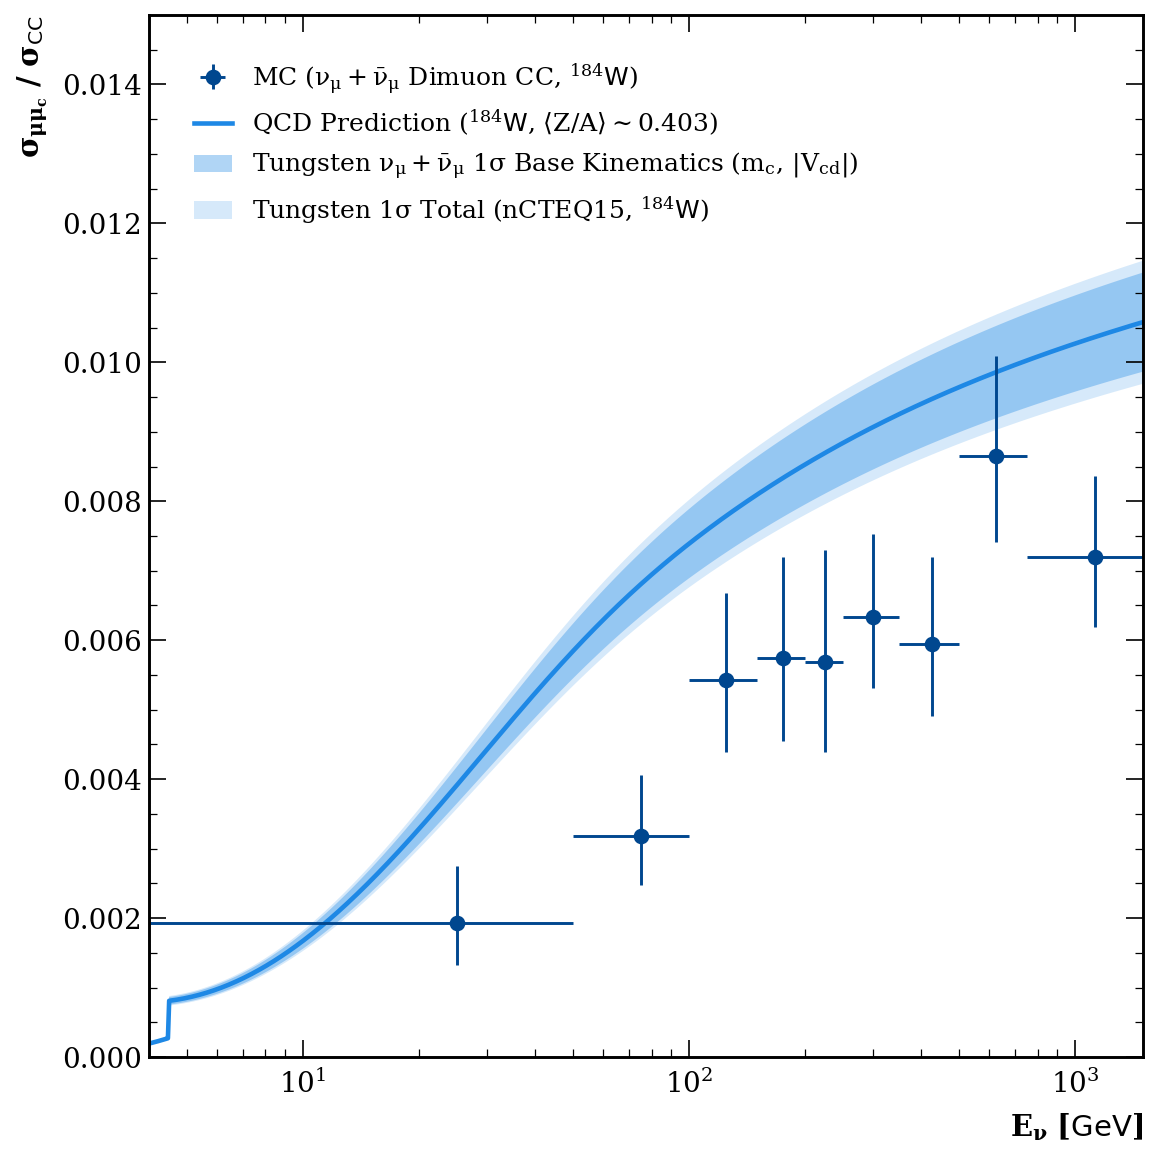

In [ ]:
# -------------------------------------------------------------------------
# Publication-Quality Charm Dimuon Reproduction Plot (Matplotlib + HEP Styling)
# -------------------------------------------------------------------------
plt.style.use("root")

fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

col_beam = "#1e88e5"       # Blue for nu_mu CC
col_em = "#455a64"         # Slate gray for Emulsion
option="nu"

# 1. Emulsion Target Uncertainty Bands (Dashed line + Hatched bands)
h_em_out = ax.fill_between(
    dim_em_out_x, dim_em_out_y - dim_em_out_eyl, dim_em_out_y + dim_em_out_eyh,
    facecolor="none", edgecolor=col_em, hatch="///", linewidth=0.6, alpha=0.65,
    label=r"Emulsion $1\sigma$ Total (nCTEQ15, emu, $\nu_\mu$)"
)
h_em_in = ax.fill_between(
    dim_em_in_x, dim_em_in_y - dim_em_in_eyl, dim_em_in_y + dim_em_in_eyh,
    facecolor="none", edgecolor=col_em, hatch=r"\\\\", linewidth=0.8, alpha=0.85,
    label=r"Emulsion $1\sigma$ Base Kinematics ($m_c,\, |V_{cd}|$)"
)
(h_em_line,) = ax.plot(
    dim_em_qcd_x, dim_em_qcd_y,
    color=col_em, lw=1.8, linestyle="--",
    label=r"QCD Prediction (Emulsion $\nu_\mu$, $\langle Z/A\rangle \sim 0.467$)"
)

# 2. Tungsten Target Uncertainty Bands (Solid lines + Solid transparent bands)
h_w_out = ax.fill_between(
    dim_w_out_x, dim_w_out_y - dim_w_out_eyl, dim_w_out_y + dim_w_out_eyh,
    color=col_beam, alpha=0.18, edgecolor="none",
    label=r"Tungsten $1\sigma$ Total (nCTEQ15, $^{184}\mathrm{W}$)"
)
h_w_in = ax.fill_between(
    dim_w_in_x, dim_w_in_y - dim_w_in_eyl, dim_w_in_y + dim_w_in_eyh,
    color=col_beam, alpha=0.35, edgecolor="none",
    label=r"Tungsten $\nu_\mu + \bar \nu_\mu$ $1\sigma$ Base Kinematics ($m_c,\, |V_{cd}|$)"
)
(h_w_line,) = ax.plot(
    dim_w_qcd_x, dim_w_qcd_y,
    color=col_beam, lw=2.2, linestyle="-",
    label=r"QCD Prediction ($^{184}\mathrm{W}$, $\langle Z/A\rangle \sim 0.403$)"
)

# # 3. Historical Measurements
# exp_styles = {
#     "NOMAD":     {"fmt": "d", "label": r"NOMAD (2013, $\nu_\mu$ CC)", "size": 6.5},
#     "CHORUS":    {"fmt": "s", "label": r"CHORUS (2011, $\nu_\mu$ CC)", "size": 6.0},
#     "CCFR":      {"fmt": "o", "label": r"CCFR (1995, $\nu_\mu$ CC)", "size": 6.0},
#     "E53A+E53B": {"fmt": "^", "label": r"E53A+E53B (1983, $\nu_\mu$ CC)", "size": 6.5},
# }
# meas_handles = []
# for exp_name in ["NOMAD", "CHORUS", "CCFR", "E53A+E53B"]:
#     if exp_name in dim_measurements:
#         px, py, p_dxl, p_dxh, p_dyl, p_dyh = dim_measurements[exp_name][:6]
#         st = exp_styles.get(exp_name, {"fmt": "o", "label": exp_name, "size": 6.0})
#         h_exp = ax.errorbar(
#             px, py, xerr=[p_dxl, p_dxh], yerr=[p_dyl, p_dyh],
#             fmt=st["fmt"], color="black", mfc="none", mec="black", mew=1.4,
#             markersize=st["size"], elinewidth=1.2, capsize=0,
#             label=st["label"],
#         )
#         meas_handles.append(h_exp)

# 4. SND@LHC MC Dimuon Points
h_mc_dim = ax.errorbar(
    dim_mc_x, dim_mc_y, xerr=[dim_mc_exl, dim_mc_exh], yerr=[dim_mc_eyl, dim_mc_eyh],
    fmt="o", color="#00478f", mfc="#00478f", mec="#00478f", mew=1.5,
    markersize=6.0, elinewidth=1.4, capsize=0,
    label=r"MC ($\nu_\mu + \bar \nu_\mu$ Dimuon CC, $^{184}\mathrm{W}$)"
)

# Axes, Limits & Formatting
ax.set_xscale("log")
ax.set_xlim(4.0, 1500.0)
ax.set_ylim(0.0, 0.015)

ax.set_xlabel(r"$E_\nu\ [\mathrm{GeV}]$", fontsize=14, loc="right", labelpad=6)
ax.set_ylabel(r"$\sigma_{\mu\mu_c}\ /\ \sigma_{\mathrm{CC}}$", fontsize=14, loc="top", labelpad=6)

# legend_handles = [h_mc_dim] + meas_handles + [h_w_line, h_w_in, h_w_out, h_em_line, h_em_in, h_em_out]
legend_handles = [h_mc_dim] + [h_w_line, h_w_in, h_w_out]
ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    frameon=False,
    facecolor="white",
    edgecolor="black",
    framealpha=0.92,
    fontsize=12
)

plt.tight_layout()
plt.show()


In [11]:
# -------------------------------------------------------------------------
# Direct Inline Rendering of Dimuon TCanvas from ROOT File
# -------------------------------------------------------------------------
canv_dim_nu = f_root.Get("Canvases/c_charm_dimuon_rate_vs_energy_nu_only")
if canv_dim_nu:
    temp_dim_path = "/tmp/c_charm_dimuon_rate_vs_energy_nu_inline.png"
    canv_dim_nu.SaveAs(temp_dim_path)
    display(Image(filename=temp_dim_path))
else:
    print("Canvas c_charm_dimuon_rate_vs_energy_nu_only not found in Canvases/")


NameError: name 'f_root' is not defined

In [ ]:
# -------------------------------------------------------------------------
# Multi-Beam Dimuon Comparison Canvas (Inclusive vs Nu vs Anti-Nu)
# -------------------------------------------------------------------------
canv_dim_comp = f_root.Get("Canvases/c_charm_dimuon_rate_vs_energy_comparison")
if canv_dim_comp:
    temp_dim_comp_path = "/tmp/c_charm_dimuon_rate_vs_energy_comp_inline.png"
    canv_dim_comp.SaveAs(temp_dim_comp_path)
    display(Image(filename=temp_dim_comp_path))
else:
    print("Canvas c_charm_dimuon_rate_vs_energy_comparison not found in Canvases/")
